# Pronóstico con una LSTM en PyTorch

Usaremos la serie mensual de manchas solares incluida en `../data/sunspots.csv`. El objetivo es predecir el siguiente mes a partir de los 24 meses anteriores.

## Entorno y protocolo

Ejecuta el notebook con el kernel **IPD434**. Selecciona CUDA cuando esté disponible. Las particiones respetan el orden temporal y el escalamiento se ajusta solo con entrenamiento.

In [1]:
from copy import deepcopy
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 2026
torch.manual_seed(SEED)
np.random.seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__)
print('Dispositivo:', device)

PyTorch: 2.11.0+cu128
Dispositivo: cuda


## Leer y dividir la serie

Separamos los primeros 70 % de los meses para entrenamiento, el siguiente 15 % para validación y el tramo final para prueba. La validación selecciona la época.

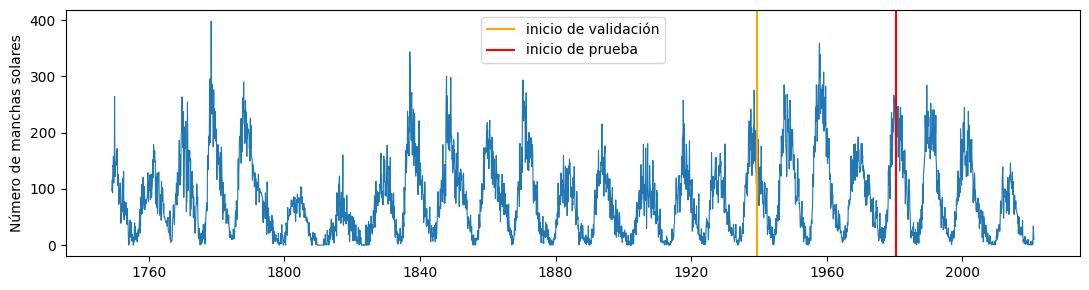

In [2]:
DATA_PATH = Path('../data/sunspots.csv')
frame = pd.read_csv(DATA_PATH, parse_dates=['Date']).sort_values('Date')
dates = frame['Date'].to_numpy()
values = frame['Monthly Mean Total Sunspot Number'].to_numpy(dtype=np.float32)

n = len(values)
train_end = int(0.70 * n)
val_end = int(0.85 * n)
train_min = float(values[:train_end].min())
train_max = float(values[:train_end].max())
scale = train_max - train_min
series = (values - train_min) / scale

plt.figure(figsize=(11, 3))
plt.plot(dates, values, linewidth=0.8)
plt.axvline(dates[train_end], color='orange', label='inicio de validación')
plt.axvline(dates[val_end], color='red', label='inicio de prueba')
plt.ylabel('Número de manchas solares')
plt.legend()
plt.tight_layout()
plt.show()

## Convertir la serie en ventanas

Cada entrada contiene 24 pasos y una característica. Para predecir el siguiente mes, la ventana de validación puede usar meses anteriores del entrenamiento. En prueba se permite usar la historia observada hasta ese momento.

In [3]:
LOOKBACK = 24

def make_windows(target_start, target_stop):
    target_indices = np.arange(max(LOOKBACK, target_start), target_stop)
    x = np.stack([series[t - LOOKBACK:t] for t in target_indices])
    y = series[target_indices]
    return (
        torch.tensor(x[:, :, None], dtype=torch.float32),
        torch.tensor(y[:, None], dtype=torch.float32),
        target_indices,
    )

x_train, y_train, train_times = make_windows(LOOKBACK, train_end)
x_val, y_val, val_times = make_windows(train_end, val_end)
x_test, y_test, test_times = make_windows(val_end, n)

train_loader = DataLoader(
    TensorDataset(x_train, y_train), batch_size=64, shuffle=True,
    generator=torch.Generator().manual_seed(SEED), num_workers=0
)
val_loader = DataLoader(TensorDataset(x_val, y_val), batch_size=128, shuffle=False)
test_loader = DataLoader(TensorDataset(x_test, y_test), batch_size=128, shuffle=False)
print('Ventana:', x_train.shape[1:], '| ejemplos:', len(x_train))

Ventana: torch.Size([24, 1]) | ejemplos: 2261


## Definir la red recurrente

`batch_first=True` usa tensores con forma `(lote, pasos, características)`. La LSTM procesa los 24 meses y la capa lineal convierte el estado del último paso en un pronóstico.

In [4]:
class SunspotLSTM(nn.Module):
    def __init__(self, hidden_size=32):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=1, hidden_size=hidden_size, batch_first=True
        )
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x):
        sequence, _ = self.lstm(x)
        return self.output(sequence[:, -1, :])

model = SunspotLSTM().to(device)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
print(model)

SunspotLSTM(
  (lstm): LSTM(1, 32, batch_first=True)
  (output): Linear(in_features=32, out_features=1, bias=True)
)


## Entrenar y seleccionar con validación

Se minimiza el error cuadrático medio. La detención temprana guarda los pesos de menor pérdida de validación, sin consultar la prueba.

Época 01 | train=0.02976 | val=0.02613
Época 02 | train=0.01362 | val=0.00979
Época 03 | train=0.00713 | val=0.00824
Época 04 | train=0.00596 | val=0.00694
Época 05 | train=0.00535 | val=0.00590
Época 06 | train=0.00491 | val=0.00532
Época 07 | train=0.00460 | val=0.00542
Época 08 | train=0.00446 | val=0.00494
Época 09 | train=0.00458 | val=0.00491
Época 10 | train=0.00433 | val=0.00493
Época 11 | train=0.00431 | val=0.00556
Época 12 | train=0.00427 | val=0.00476
Época 13 | train=0.00423 | val=0.00505
Época 14 | train=0.00417 | val=0.00450
Época 15 | train=0.00415 | val=0.00487
Época 16 | train=0.00424 | val=0.00448
Época 17 | train=0.00408 | val=0.00473
Época 18 | train=0.00421 | val=0.00443
Época 19 | train=0.00430 | val=0.00439
Época 20 | train=0.00410 | val=0.00443
Época 21 | train=0.00411 | val=0.00502
Época 22 | train=0.00412 | val=0.00433
Época 23 | train=0.00406 | val=0.00451
Época 24 | train=0.00400 | val=0.00438
Época 25 | train=0.00402 | val=0.00436
Época 26 | train=0.00408 

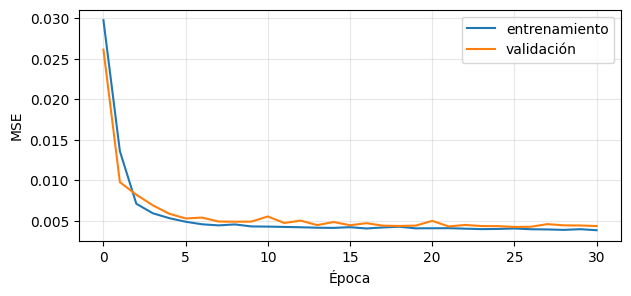

In [5]:
def evaluate(model, loader):
    model.eval()
    loss_sum, count = 0.0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            loss = criterion(model(xb), yb)
            loss_sum += loss.item() * len(yb)
            count += len(yb)
    return loss_sum / count

MAX_EPOCHS = 50
PATIENCE = 5
best_val_loss = float('inf')
best_state = deepcopy(model.state_dict())
waiting = 0
history = {'train_loss': [], 'val_loss': []}

for epoch in range(1, MAX_EPOCHS + 1):
    model.train()
    train_sum, train_count = 0.0, 0
    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad(set_to_none=True)
        loss = criterion(model(xb), yb)
        loss.backward()
        optimizer.step()
        train_sum += loss.item() * len(yb)
        train_count += len(yb)

    train_loss = train_sum / train_count
    val_loss = evaluate(model, val_loader)
    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    print(f'Época {epoch:02d} | train={train_loss:.5f} | val={val_loss:.5f}')

    if val_loss < best_val_loss - 1e-5:
        best_val_loss = val_loss
        best_state = deepcopy(model.state_dict())
        waiting = 0
    else:
        waiting += 1
        if waiting >= PATIENCE:
            print('Detención temprana.')
            break

model.load_state_dict(best_state)
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(history['train_loss'], label='entrenamiento')
ax.plot(history['val_loss'], label='validación')
ax.set(xlabel='Época', ylabel='MSE')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## Evaluar el pronóstico

Comparamos la LSTM con una referencia simple que predice el último valor observado. Las métricas se expresan en la unidad original de la serie.

RMSE LSTM: 23.00
RMSE último valor: 25.18


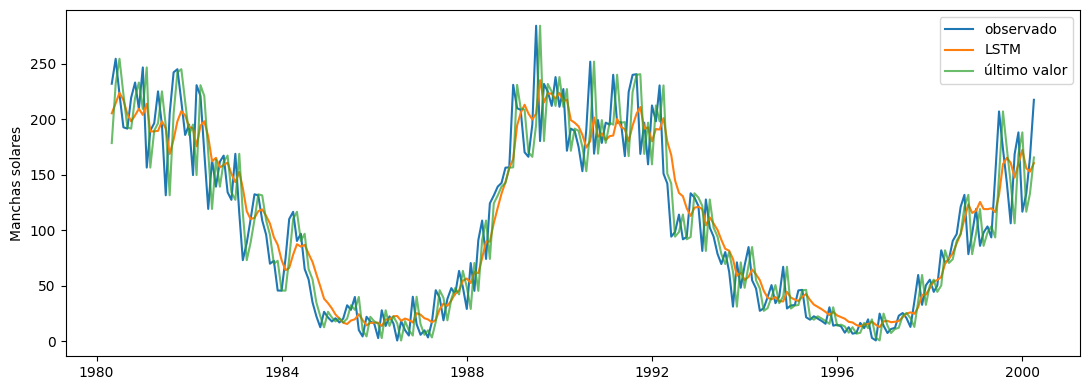

In [6]:
model.eval()
pred_scaled = []
with torch.no_grad():
    for xb, _ in test_loader:
        pred_scaled.append(model(xb.to(device)).cpu().numpy())
pred_scaled = np.concatenate(pred_scaled).ravel()
actual = y_test.numpy().ravel() * scale + train_min
prediction = pred_scaled * scale + train_min
persistence = x_test[:, -1, 0].numpy() * scale + train_min

rmse_lstm = np.sqrt(np.mean((actual - prediction) ** 2))
rmse_persistence = np.sqrt(np.mean((actual - persistence) ** 2))
print(f'RMSE LSTM: {rmse_lstm:.2f}')
print(f'RMSE último valor: {rmse_persistence:.2f}')

show = min(240, len(test_times))
plt.figure(figsize=(11, 4))
plt.plot(dates[test_times[:show]], actual[:show], label='observado')
plt.plot(dates[test_times[:show]], prediction[:show], label='LSTM')
plt.plot(dates[test_times[:show]], persistence[:show], label='último valor', alpha=0.7)
plt.ylabel('Manchas solares')
plt.legend()
plt.tight_layout()
plt.show()